# Fashion-MNIST Neural Network Experiments.

In [ ]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow version: 2.21.0


## Load and prepare Fashion-MNIST

In [2]:
(x_full, y_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

x_train, x_val, y_train, y_val = train_test_split(
    x_full,
    y_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_full
)

# Convert pixel intensities from [0, 255] to [0, 1] and use float32.
x_train = x_train.astype("float32") / 255.0
x_val   = x_val.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(f"Training images:   {x_train.shape} | labels: {y_train.shape}")
print(f"Validation images: {x_val.shape} | labels: {y_val.shape}")
print(f"Test images:       {x_test.shape} | labels: {y_test.shape}")
print("Number of classes:", len(class_names))
print("Pixel range:", float(x_train.min()), "to", float(x_train.max()))

Training images:   (48000, 28, 28) | labels: (48000,)
Validation images: (12000, 28, 28) | labels: (12000,)
Test images:       (10000, 28, 28) | labels: (10000,)
Number of classes: 10
Pixel range: 0.0 to 1.0


# Task 1 — Explore the Dataset


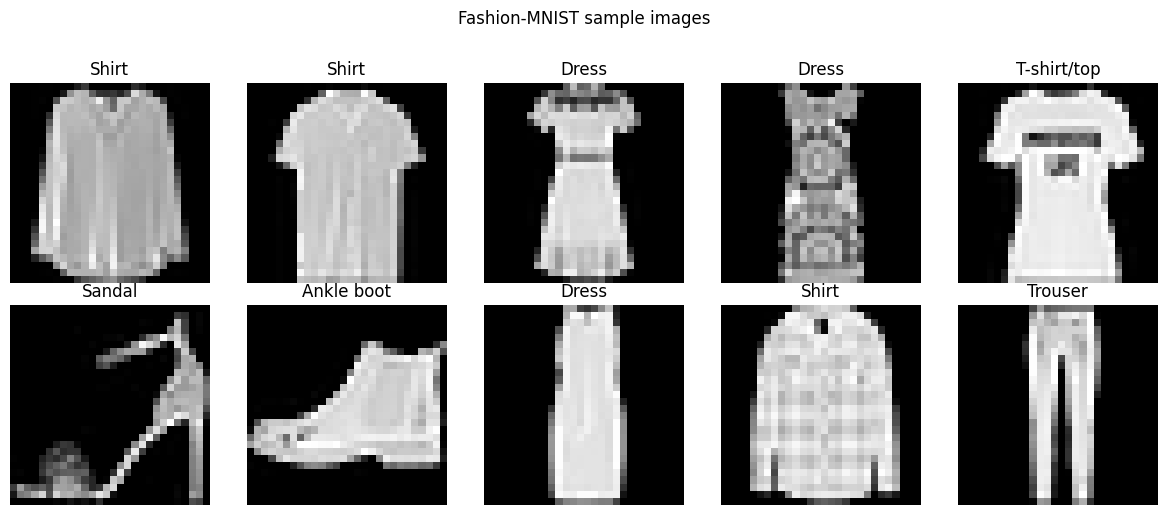

,Class ID,Class,Training Images
0,0,T-shirt/top,4800
1,1,Trouser,4800
2,2,Pullover,4800
3,3,Dress,4800
4,4,Coat,4800
5,5,Sandal,4800
6,6,Shirt,4800
7,7,Sneaker,4800
8,8,Bag,4800
9,9,Ankle boot,4800


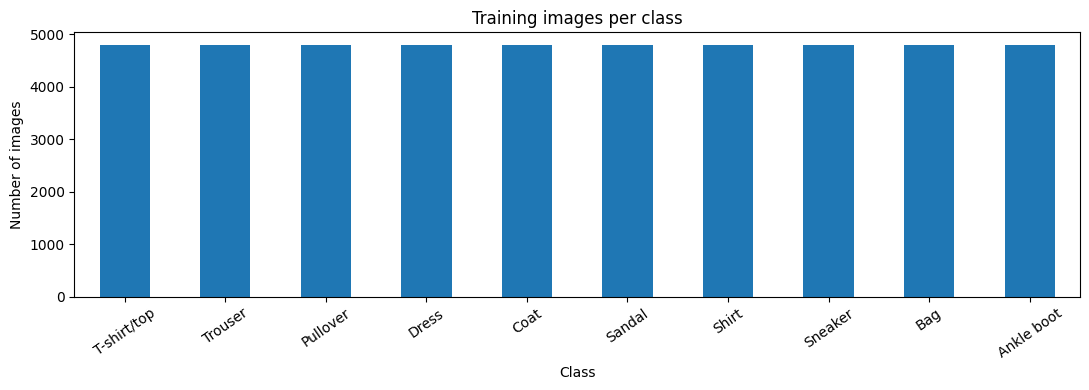

Class-count range: 4800 to 4800
Balanced by count: True


In [3]:
# Display 10 examples with their labels.
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_names[int(y_train[i])])
    ax.axis("off")
fig.suptitle("Fashion-MNIST sample images", y=1.02)
plt.tight_layout()
plt.show()

class_counts = pd.Series(y_train).value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Class ID": range(len(class_names)),
    "Class": class_names,
    "Training Images": class_counts.values
})
display(class_distribution)

ax = class_distribution.plot(
    x="Class", y="Training Images", kind="bar",
    legend=False, figsize=(11, 4), rot=35
)
ax.set_title("Training images per class")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
plt.tight_layout()
plt.show()

print("Class-count range:", int(class_counts.min()), "to", int(class_counts.max()))
print("Balanced by count:", bool(class_counts.max() - class_counts.min() <= 1))

**Task 1 — Answer guide:** Normalization scales pixel values to `[0, 1]`, which usually makes optimization more stable. Fashion-MNIST is balanced by class in its original training set (each class has the same number of examples); the stratified split preserves similar class proportions in the training and validation sets. Confirm this using the displayed counts.

# Shared helper functions


In [5]:
def build_model(
    hidden_units=32,
    activation="relu",
    optimizer="adam",
    learning_rate=None
):
    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(hidden_units, activation=activation),
        layers.Dense(10, activation="softmax")
    ])

    if isinstance(optimizer, str):
        if optimizer.lower() == "adam":
            opt = keras.optimizers.Adam(
                learning_rate=learning_rate if learning_rate is not None else 0.001
            )
        elif optimizer.lower() == "sgd":
            opt = keras.optimizers.SGD(
                learning_rate=learning_rate if learning_rate is not None else 0.01
            )
        else:
            raise ValueError(f"Unsupported optimizer: {optimizer}")
    else:
        opt = optimizer

    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def plot_history(history, title="Training history"):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(hist["loss"], label="Training loss")
    axes[0].plot(hist["val_loss"], label="Validation loss")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(hist["accuracy"], label="Training accuracy")
    axes[1].plot(hist["val_accuracy"], label="Validation accuracy")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def best_val_accuracy(history):
    return float(np.max(history.history["val_accuracy"]))


def best_val_loss(history):
    return float(np.min(history.history["val_loss"]))


experiment_results = []
experiment_histories = {}
experiment_models = {}

def record_experiment(name, setting, history, model, elapsed_seconds):
    row = {
        "Experiment": name,
        "Setting changed": setting,
        "Best validation accuracy": best_val_accuracy(history),
        "Best validation loss": best_val_loss(history),
        "Final training accuracy": float(history.history["accuracy"][-1]),
        "Final validation accuracy": float(history.history["val_accuracy"][-1]),
        "Epochs trained": len(history.history["loss"]),
        "Training time (seconds)": round(elapsed_seconds, 2)
    }
    experiment_results.append(row)
    experiment_histories[name] = history
    experiment_models[name] = model
    return row

# Task 2 — Train a Baseline Model


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.8038 - loss: 0.5726 - val_accuracy: 0.8460 - val_loss: 0.4430
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8525 - loss: 0.4248 - val_accuracy: 0.8634 - val_loss: 0.3938
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8627 - loss: 0.3867 - val_accuracy: 0.8699 - val_loss: 0.3737
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8710 - loss: 0.3634 - val_accuracy: 0.8727 - val_loss: 0.3624
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8776 - loss: 0.3458 - val_accuracy: 0.8751 - val_loss: 0.3536
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8813 - loss: 0.3317 - val_accuracy: 0.8759 - val_loss: 0.3500
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8854 - loss: 0.3207 - val_accuracy: 0.8767 - val_loss: 0.3469
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8879 - loss: 0.3113 - 

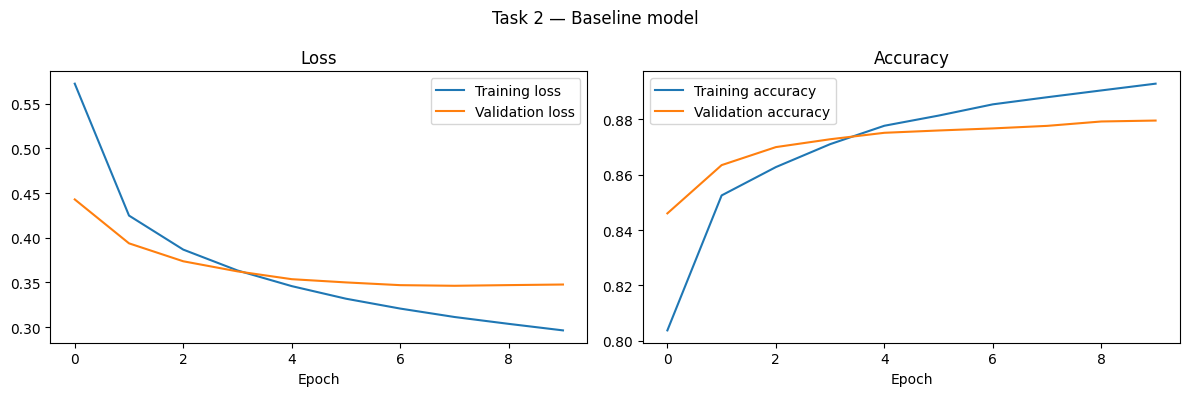

Final training accuracy:   0.8928
Final validation accuracy: 0.8795
Baseline test accuracy:    0.8632


In [6]:
baseline_model = build_model(hidden_units=32, activation="relu", optimizer="adam")
baseline_model.summary()

start = time.perf_counter()
baseline_history = baseline_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=1
)
baseline_time = time.perf_counter() - start

record_experiment(
    "Baseline",
    "32 neurons; ReLU; Adam; batch=32; epochs=10",
    baseline_history,
    baseline_model,
    baseline_time
)
plot_history(baseline_history, "Task 2 — Baseline model")

test_loss_baseline, test_acc_baseline = baseline_model.evaluate(x_test, y_test, verbose=0)
print(f"Final training accuracy:   {baseline_history.history['accuracy'][-1]:.4f}")
print(f"Final validation accuracy: {baseline_history.history['val_accuracy'][-1]:.4f}")
print(f"Baseline test accuracy:    {test_acc_baseline:.4f}")

# Task 3 — Analyze Predictions


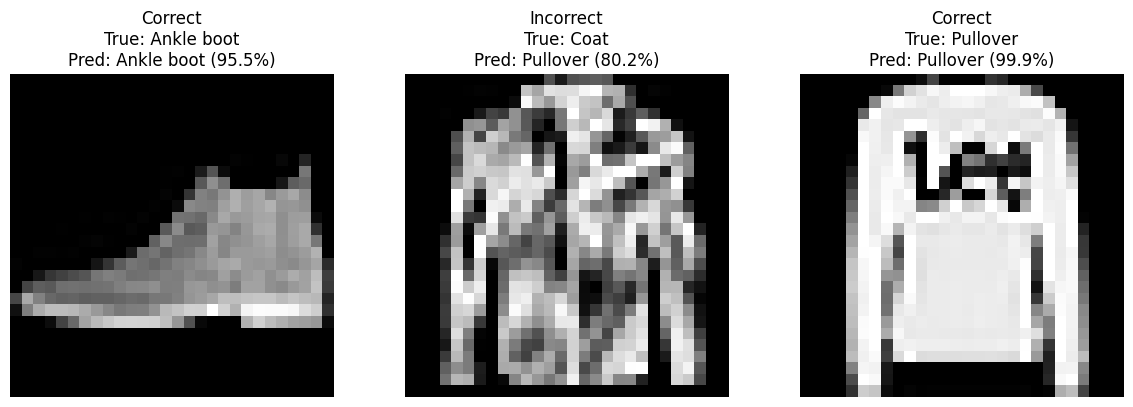

In [7]:
test_probabilities = baseline_model.predict(x_test, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)
correct_indices = np.flatnonzero(test_predictions == y_test)
incorrect_indices = np.flatnonzero(test_predictions != y_test)

chosen = []
if len(correct_indices):
    chosen.append(int(correct_indices[0]))
if len(incorrect_indices):
    chosen.append(int(incorrect_indices[0]))

for idx in range(len(y_test)):
    if len(chosen) >= 3:
        break
    if idx not in chosen:
        chosen.append(idx)

fig, axes = plt.subplots(1, len(chosen), figsize=(4 * len(chosen), 4))
if len(chosen) == 1:
    axes = [axes]

for ax, idx in zip(axes, chosen):
    true_label = int(y_test[idx])
    pred_label = int(test_predictions[idx])
    confidence = float(test_probabilities[idx, pred_label])
    status = "Correct" if true_label == pred_label else "Incorrect"
    ax.imshow(x_test[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"{status}\nTrue: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]} ({confidence:.1%})"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

# Task 4 — Compare Epoch Counts


Epochs=5: best val accuracy=0.8719; best val loss=0.3725; time=11.0s
Epochs=10: best val accuracy=0.8737; best val loss=0.3592; time=21.0s
Epochs=20: best val accuracy=0.8796; best val loss=0.3422; time=40.2s


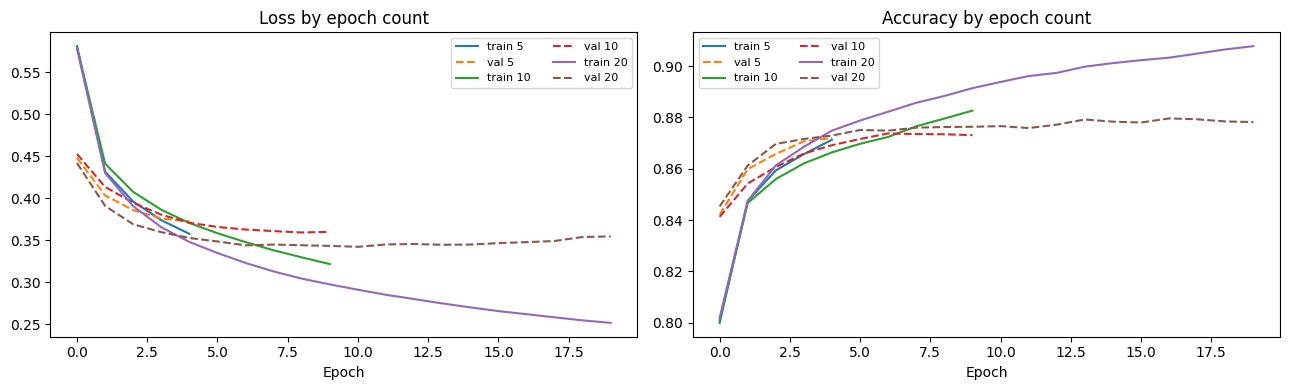

,Epochs,Best validation accuracy,Best validation loss,Final training accuracy,Final validation accuracy
0,5,0.871917,0.372455,0.871312,0.871917
1,10,0.873750,0.359220,0.882625,0.873083
2,20,0.879583,0.342155,0.907729,0.878167


In [8]:
epoch_histories = {}

for epoch_count in [5, 10, 20]:
    model = build_model(hidden_units=32, activation="relu", optimizer="adam")
    start = time.perf_counter()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=epoch_count,
        batch_size=32,
        verbose=0
    )
    elapsed = time.perf_counter() - start
    name = f"Epochs={epoch_count}"
    epoch_histories[epoch_count] = history
    record_experiment(name, f"epochs={epoch_count}", history, model, elapsed)
    print(f"{name}: best val accuracy={best_val_accuracy(history):.4f}; "
          f"best val loss={best_val_loss(history):.4f}; time={elapsed:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n, h in epoch_histories.items():
    axes[0].plot(h.history["loss"], label=f"train {n}")
    axes[0].plot(h.history["val_loss"], linestyle="--", label=f"val {n}")
    axes[1].plot(h.history["accuracy"], label=f"train {n}")
    axes[1].plot(h.history["val_accuracy"], linestyle="--", label=f"val {n}")
axes[0].set_title("Loss by epoch count")
axes[0].set_xlabel("Epoch")
axes[0].legend(ncol=2, fontsize=8)
axes[1].set_title("Accuracy by epoch count")
axes[1].set_xlabel("Epoch")
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

epoch_summary = pd.DataFrame([
    {
        "Epochs": n,
        "Best validation accuracy": best_val_accuracy(h),
        "Best validation loss": best_val_loss(h),
        "Final training accuracy": h.history["accuracy"][-1],
        "Final validation accuracy": h.history["val_accuracy"][-1]
    }
    for n, h in epoch_histories.items()
])
display(epoch_summary)

# Task 5 — EarlyStopping Experiment


No EarlyStopping: epochs trained=40; best val loss=0.3331; final val accuracy=0.8811
EarlyStopping patience=3: epochs trained=11; best val loss=0.3477; final val accuracy=0.8777
EarlyStopping patience=5: epochs trained=15; best val loss=0.3363; final val accuracy=0.8818


,Run,Epochs trained,Best validation loss,Final validation accuracy
0,No EarlyStopping,40,0.333119,0.881083
1,EarlyStopping patience=3,11,0.347709,0.877750
2,EarlyStopping patience=5,15,0.336309,0.881833


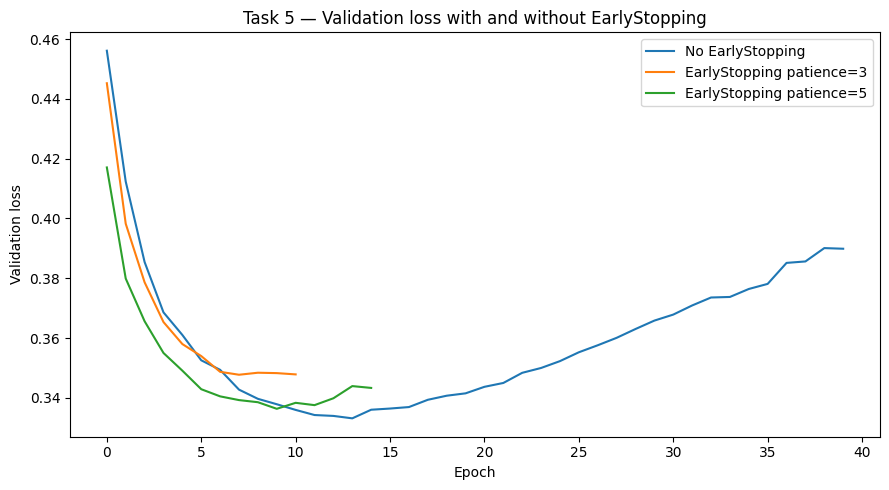

In [9]:
earlystop_configs = [
    ("No EarlyStopping", None),
    ("EarlyStopping patience=3", 3),
    ("EarlyStopping patience=5", 5)
]
earlystop_histories = {}

for name, patience in earlystop_configs:
    model = build_model(hidden_units=32, activation="relu", optimizer="adam")
    callbacks = []
    if patience is not None:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=patience,
            restore_best_weights=True
        ))

    start = time.perf_counter()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=40,
        batch_size=32,
        callbacks=callbacks,
        verbose=0
    )
    elapsed = time.perf_counter() - start
    earlystop_histories[name] = history
    record_experiment(name, f"EarlyStopping patience={patience}", history, model, elapsed)
    print(f"{name}: epochs trained={len(history.history['loss'])}; "
          f"best val loss={best_val_loss(history):.4f}; "
          f"final val accuracy={history.history['val_accuracy'][-1]:.4f}")

earlystop_summary = pd.DataFrame([
    {
        "Run": name,
        "Epochs trained": len(h.history["loss"]),
        "Best validation loss": best_val_loss(h),
        "Final validation accuracy": h.history["val_accuracy"][-1]
    }
    for name, h in earlystop_histories.items()
])
display(earlystop_summary)

plt.figure(figsize=(9, 5))
for name, h in earlystop_histories.items():
    plt.plot(h.history["val_loss"], label=name)
plt.title("Task 5 — Validation loss with and without EarlyStopping")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.tight_layout()
plt.show()

# Task 6 — Hidden Neurons Experiment


Hidden neurons=16: train acc=0.8708; val acc=0.8700; time=20.0s
Hidden neurons=32: train acc=0.8875; val acc=0.8770; time=30.2s
Hidden neurons=128: train acc=0.9128; val acc=0.8873; time=25.4s


,Hidden neurons,Final training accuracy,Best validation accuracy,Training time (seconds)
0,16,0.870833,0.87000,20.00
1,32,0.887500,0.87700,30.24
2,128,0.912750,0.88825,25.44


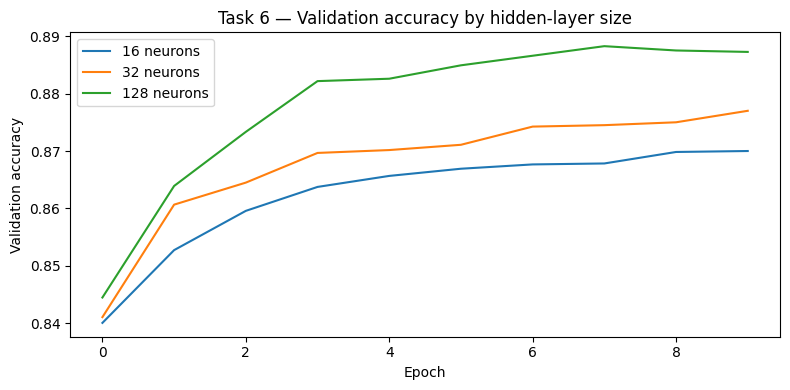

In [10]:
neuron_histories = {}

for units in [16, 32, 128]:
    model = build_model(hidden_units=units, activation="relu", optimizer="adam")
    start = time.perf_counter()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=10,
        batch_size=32,
        verbose=0
    )
    elapsed = time.perf_counter() - start
    name = f"Hidden neurons={units}"
    neuron_histories[units] = history
    record_experiment(name, f"hidden_units={units}", history, model, elapsed)
    print(f"{name}: train acc={history.history['accuracy'][-1]:.4f}; "
          f"val acc={history.history['val_accuracy'][-1]:.4f}; time={elapsed:.1f}s")

display(pd.DataFrame([
    {
        "Hidden neurons": units,
        "Final training accuracy": h.history["accuracy"][-1],
        "Best validation accuracy": best_val_accuracy(h),
        "Training time (seconds)": next(r["Training time (seconds)"] for r in experiment_results if r["Experiment"] == f"Hidden neurons={units}")
    }
    for units, h in neuron_histories.items()
]))

plt.figure(figsize=(8, 4))
for units, h in neuron_histories.items():
    plt.plot(h.history["val_accuracy"], label=f"{units} neurons")
plt.title("Task 6 — Validation accuracy by hidden-layer size")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# Task 7 — Batch Size Experiment

Compare batch sizes 8, 32, and 128. Architecture, optimizer, and epoch count are fixed.

Batch size=8: best val acc=0.8568; approx. updates/epoch=6000; seconds/epoch=7.58
Batch size=32: best val acc=0.8765; approx. updates/epoch=1500; seconds/epoch=2.04
Batch size=128: best val acc=0.8725; approx. updates/epoch=375; seconds/epoch=0.71


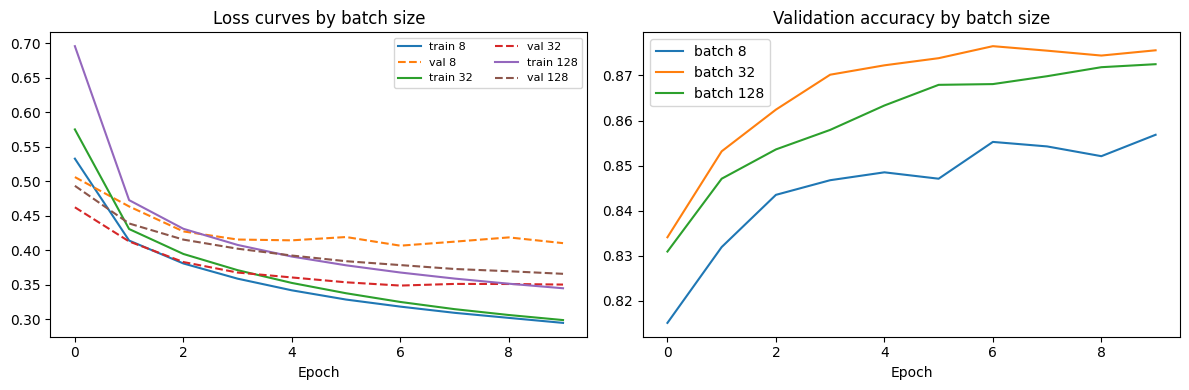

In [11]:
batch_histories = {}

for batch in [8, 32, 128]:
    model = build_model(hidden_units=32, activation="relu", optimizer="adam")
    start = time.perf_counter()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=10,
        batch_size=batch,
        verbose=0
    )
    elapsed = time.perf_counter() - start
    name = f"Batch size={batch}"
    batch_histories[batch] = history
    record_experiment(name, f"batch_size={batch}", history, model, elapsed)
    seconds_per_epoch = elapsed / len(history.history["loss"])
    updates_per_epoch = int(np.ceil(len(x_train) / batch))
    print(f"{name}: best val acc={best_val_accuracy(history):.4f}; "
          f"approx. updates/epoch={updates_per_epoch}; "
          f"seconds/epoch={seconds_per_epoch:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for batch, h in batch_histories.items():
    axes[0].plot(h.history["loss"], label=f"train {batch}")
    axes[0].plot(h.history["val_loss"], linestyle="--", label=f"val {batch}")
    axes[1].plot(h.history["val_accuracy"], label=f"batch {batch}")
axes[0].set_title("Loss curves by batch size")
axes[0].set_xlabel("Epoch")
axes[0].legend(ncol=2, fontsize=8)
axes[1].set_title("Validation accuracy by batch size")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

# Task 8 — Optimizer Comparison


SGD: validation accuracy after 10 epochs=0.8493; best validation accuracy=0.8493
SGD + Momentum: validation accuracy after 10 epochs=0.8674; best validation accuracy=0.8674
Adam: validation accuracy after 10 epochs=0.8788; best validation accuracy=0.8789


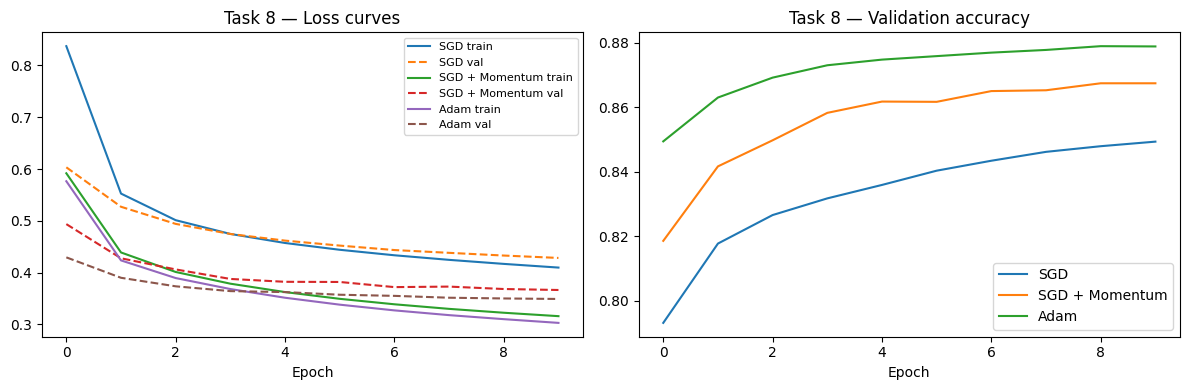

In [12]:
optimizer_configs = [
    ("SGD", keras.optimizers.SGD(learning_rate=0.01)),
    ("SGD + Momentum", keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)),
    ("Adam", keras.optimizers.Adam(learning_rate=0.001))
]
optimizer_histories = {}

for name, optimizer in optimizer_configs:
    model = build_model(hidden_units=32, activation="relu", optimizer=optimizer)
    start = time.perf_counter()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=10,
        batch_size=32,
        verbose=0
    )
    elapsed = time.perf_counter() - start
    optimizer_histories[name] = history
    record_experiment(f"Optimizer: {name}", f"optimizer={name}", history, model, elapsed)
    print(f"{name}: validation accuracy after 10 epochs="
          f"{history.history['val_accuracy'][-1]:.4f}; "
          f"best validation accuracy={best_val_accuracy(history):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in optimizer_histories.items():
    axes[0].plot(h.history["loss"], label=f"{name} train")
    axes[0].plot(h.history["val_loss"], linestyle="--", label=f"{name} val")
    axes[1].plot(h.history["val_accuracy"], label=name)
axes[0].set_title("Task 8 — Loss curves")
axes[0].set_xlabel("Epoch")
axes[0].legend(fontsize=8)
axes[1].set_title("Task 8 — Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

# Task 9 — Activation Function Comparison


ReLU: best validation accuracy=0.8801; final validation accuracy=0.8801
Tanh: best validation accuracy=0.8805; final validation accuracy=0.8805
GELU (optional): best validation accuracy=0.8775; final validation accuracy=0.8775


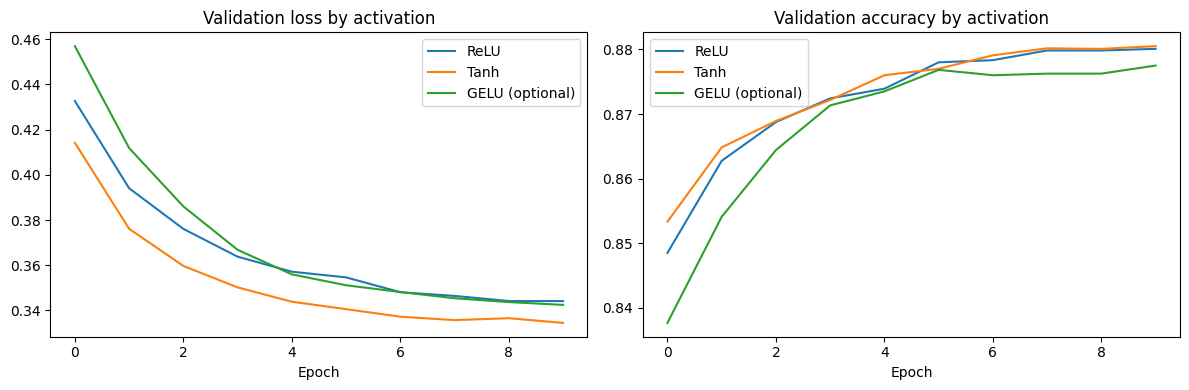

In [13]:
activation_configs = [("ReLU", "relu"), ("Tanh", "tanh"), ("GELU (optional)", "gelu")]
activation_histories = {}

for name, activation in activation_configs:
    model = build_model(hidden_units=32, activation=activation, optimizer="adam")
    start = time.perf_counter()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=10,
        batch_size=32,
        verbose=0
    )
    elapsed = time.perf_counter() - start
    activation_histories[name] = history
    record_experiment(f"Activation: {name}", f"hidden activation={activation}", history, model, elapsed)
    print(f"{name}: best validation accuracy={best_val_accuracy(history):.4f}; "
          f"final validation accuracy={history.history['val_accuracy'][-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in activation_histories.items():
    axes[0].plot(h.history["val_loss"], label=name)
    axes[1].plot(h.history["val_accuracy"], label=name)
axes[0].set_title("Validation loss by activation")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].set_title("Validation accuracy by activation")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

# Experiment Comparison Table


In [14]:
results_df = pd.DataFrame(experiment_results)
display(
    results_df.sort_values("Best validation accuracy", ascending=False)
    .reset_index(drop=True)
    .style.format({
        "Best validation accuracy": "{:.4f}",
        "Best validation loss": "{:.4f}",
        "Final training accuracy": "{:.4f}",
        "Final validation accuracy": "{:.4f}",
        "Training time (seconds)": "{:.2f}"
    })
)

,Experiment,Setting changed,Best validation accuracy,Best validation loss,Final training accuracy,Final validation accuracy,Epochs trained,Training time (seconds)
0,Hidden neurons=128,hidden_units=128,0.8882,0.3187,0.9128,0.8873,10,25.44
1,No EarlyStopping,EarlyStopping patience=None,0.8827,0.3331,0.9229,0.8811,40,80.95
2,EarlyStopping patience=5,EarlyStopping patience=5,0.8818,0.3363,0.9049,0.8818,15,30.32
3,Activation: Tanh,hidden activation=tanh,0.8805,0.3345,0.8960,0.8805,10,22.45
4,Activation: ReLU,hidden activation=relu,0.8801,0.3441,0.8897,0.8801,10,20.97
5,Epochs=20,epochs=20,0.8796,0.3422,0.9077,0.8782,20,40.22
6,Baseline,32 neurons; ReLU; Adam; batch=32; epochs=10,0.8795,0.3462,0.8928,0.8795,10,22.83
7,Optimizer: Adam,optimizer=Adam,0.8789,0.3490,0.8900,0.8788,10,21.55
8,EarlyStopping patience=3,EarlyStopping patience=3,0.8777,0.3477,0.8934,0.8777,11,22.47
9,Activation: GELU (optional),hidden activation=gelu,0.8775,0.3425,0.8920,0.8775,10,21.04


# Task 10 — Evaluate the Final Model


Selected configuration: Hidden neurons=128
Selection based on best validation accuracy: 0.8882
Final test loss: 0.3608
Final test accuracy: 0.8761


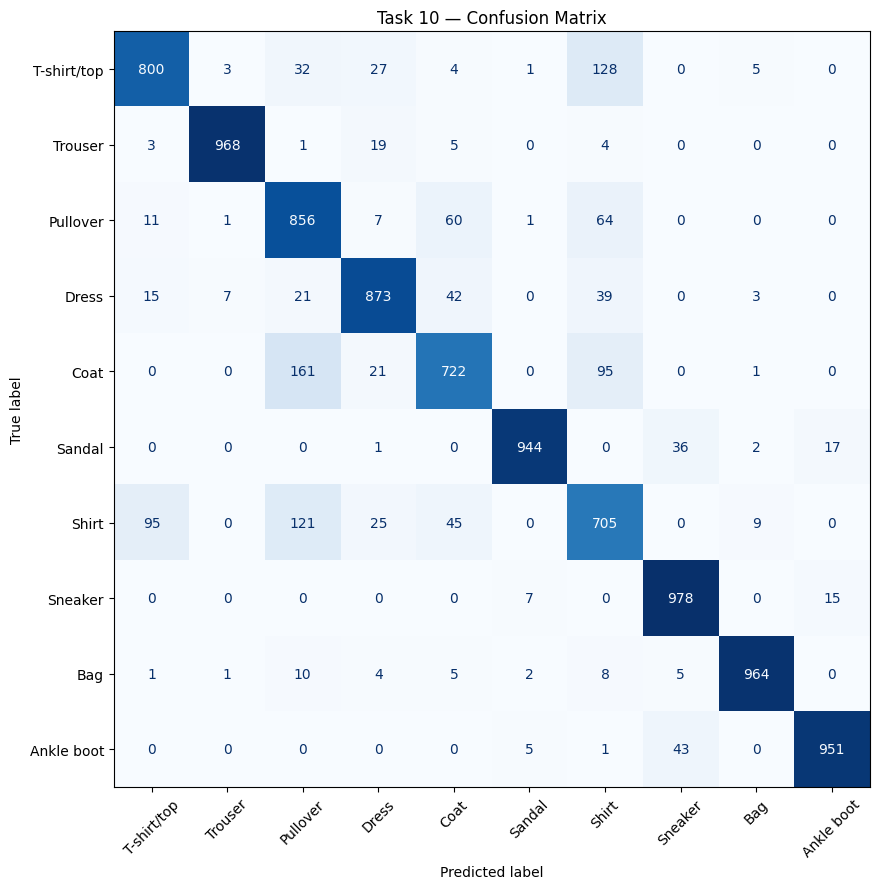

              precision    recall  f1-score   support

 T-shirt/top     0.8649    0.8000    0.8312      1000
     Trouser     0.9878    0.9680    0.9778      1000
    Pullover     0.7121    0.8560    0.7775      1000
       Dress     0.8936    0.8730    0.8832      1000
        Coat     0.8177    0.7220    0.7669      1000
      Sandal     0.9833    0.9440    0.9633      1000
       Shirt     0.6753    0.7050    0.6898      1000
     Sneaker     0.9209    0.9780    0.9486      1000
         Bag     0.9797    0.9640    0.9718      1000
  Ankle boot     0.9674    0.9510    0.9592      1000

    accuracy                         0.8761     10000
   macro avg     0.8803    0.8761    0.8769     10000
weighted avg     0.8803    0.8761    0.8769     10000



In [15]:
best_row = max(experiment_results, key=lambda row: row["Best validation accuracy"])
best_experiment_name = best_row["Experiment"]
final_model = experiment_models[best_experiment_name]

print("Selected configuration:", best_experiment_name)
print("Selection based on best validation accuracy:", f"{best_row['Best validation accuracy']:.4f}")

final_test_loss, final_test_accuracy = final_model.evaluate(x_test, y_test, verbose=0)
print(f"Final test loss: {final_test_loss:.4f}")
print(f"Final test accuracy: {final_test_accuracy:.4f}")

final_probabilities = final_model.predict(x_test, verbose=0)
final_predictions = np.argmax(final_probabilities, axis=1)

cm = confusion_matrix(y_test, final_predictions, labels=np.arange(10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(11, 9))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title("Task 10 — Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, final_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
))

## Find two classes most often confused


Most frequent off-diagonal confusion pairs:
True Coat predicted as Pullover: 161 images
True T-shirt/top predicted as Shirt: 128 images


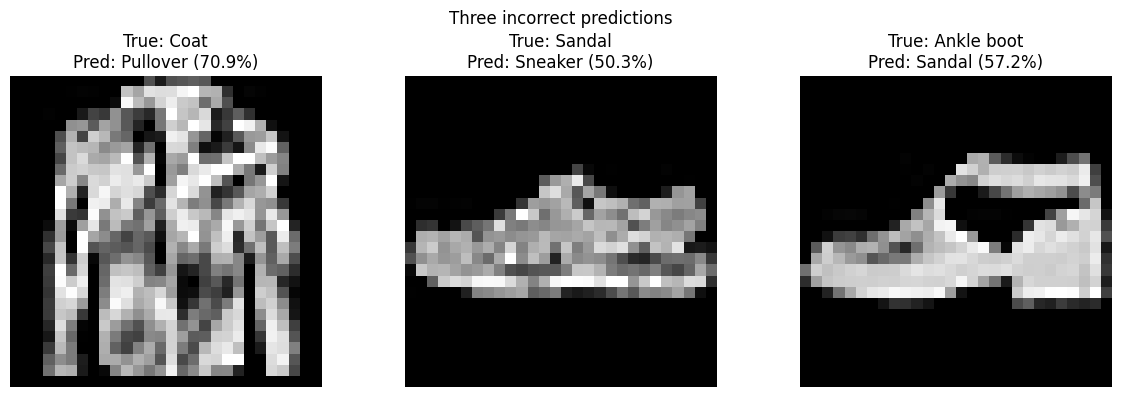

In [16]:
cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)

top_pairs = []
for flat_idx in np.argsort(cm_offdiag.ravel())[::-1]:
    true_id, pred_id = np.unravel_index(flat_idx, cm_offdiag.shape)
    count = int(cm_offdiag[true_id, pred_id])
    if count == 0:
        break
    pair = (true_id, pred_id)
    if pair not in top_pairs:
        top_pairs.append(pair)
    if len(top_pairs) == 2:
        break

print("Most frequent off-diagonal confusion pairs:")
for true_id, pred_id in top_pairs:
    print(f"True {class_names[true_id]} predicted as {class_names[pred_id]}: "
          f"{cm[true_id, pred_id]} images")

wrong_indices = np.flatnonzero(final_predictions != y_test)
display_indices = wrong_indices[:3]

if len(display_indices) == 0:
    print("No incorrect predictions were found in the test set.")
else:
    fig, axes = plt.subplots(1, len(display_indices), figsize=(4 * len(display_indices), 4))
    if len(display_indices) == 1:
        axes = [axes]
    for ax, idx in zip(axes, display_indices):
        true_id = int(y_test[idx])
        pred_id = int(final_predictions[idx])
        confidence = float(final_probabilities[idx, pred_id])
        ax.imshow(x_test[idx], cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"True: {class_names[true_id]}\n"
            f"Pred: {class_names[pred_id]} ({confidence:.1%})"
        )
        ax.axis("off")
    plt.suptitle("Three incorrect predictions")
    plt.tight_layout()
    plt.show()